# Tier 3: American options, hands on

An **American** option can be exercised at any time before expiry, not only on the expiry date.
That freedom is worth something, and neither the Tier 1 formula nor plain Monte Carlo (Tier 2)
can price it, because at every moment the holder must decide: exercise now, or wait?

The trick is to work **backwards from expiry**. At expiry we know the value (the payoff). One step
earlier, the option is worth the better of two things: waiting (the average value one step later,
discounted) or exercising now. Repeat until today. Two ways to do that:

- a **binomial tree** (Cox-Ross-Rubinstein): the stock goes up or down at each step
- a **PDE grid** (Crank-Nicolson): the Black-Scholes equation solved on a grid of prices and times

Both are checked against Tier 1 on European options, and against each other on American ones.
Running example: Hull's American put, S = 50, K = 50, T = 5 months, r = 10%, σ = 40%.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ope import backward_step, crr_params, crr_price, greeks, pde_price, pde_solve, price
from ope.monte_carlo import payoff
from ope.plots import plot_exercise_boundary, plot_tree_convergence

S, K, T, r, sigma = 50.0, 50.0, 5 / 12, 0.10, 0.40

## 1. A 5-step tree, drawn

At each step the stock goes up by a factor $u = e^{\sigma\sqrt{\Delta t}}$ or down by
$d = 1/u$. The up probability $p = (e^{r\Delta t} - d)/(u - d)$ is chosen so that the stock grows
at $r$ on average: the risk-neutral world again. Each node below shows the stock price and the
option value; the **red** nodes are where exercising early is better than waiting.

dt = 0.0833, u = 1.1224, d = 0.8909, p = 0.5073, disc = 0.9917


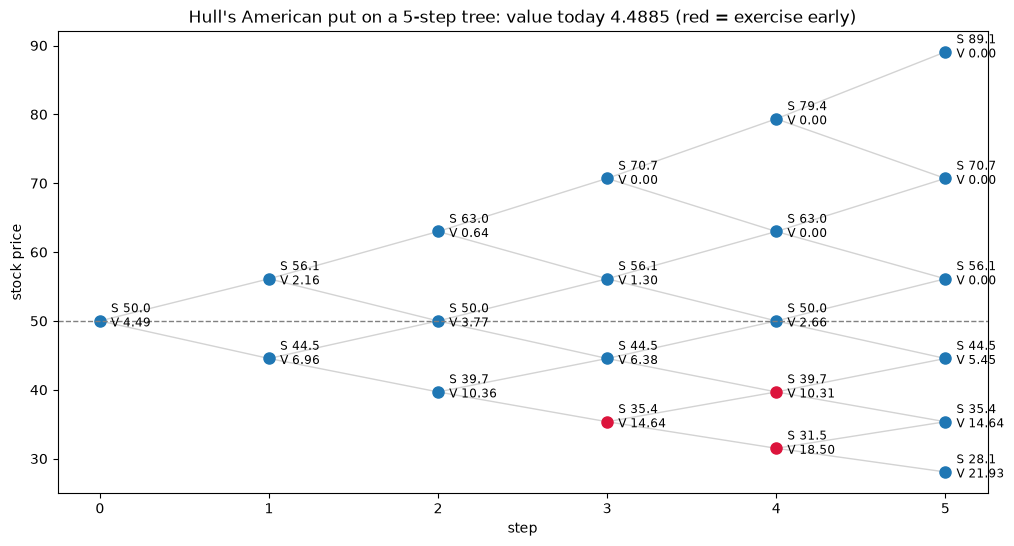

In [2]:
n = 5
c = crr_params(T, r, sigma, n)
print(f"dt = {c.dt:.4f}, u = {c.u:.4f}, d = {c.d:.4f}, p = {c.p:.4f}, disc = {c.disc:.4f}")

stock = [S * c.u ** (2 * np.arange(i + 1) - i) for i in range(n + 1)]
values = [None] * (n + 1)
values[n] = payoff("put", stock[n], K)
early = [np.zeros(i + 1, dtype=bool) for i in range(n + 1)]
for i in range(n - 1, -1, -1):
    wait = backward_step(values[i + 1], c.p, c.disc)
    now = payoff("put", stock[i], K)
    values[i] = np.maximum(wait, now)
    early[i] = now > wait

fig, ax = plt.subplots(figsize=(12, 6))
for i in range(n + 1):
    for j in range(i + 1):
        if i < n:
            for jj in (j, j + 1):
                ax.plot(
                    [i, i + 1], [stock[i][j], stock[i + 1][jj]], color="lightgray", lw=1, zorder=0
                )
        color = "crimson" if early[i][j] else "tab:blue"
        ax.plot(i, stock[i][j], "o", color=color, ms=8)
        ax.annotate(
            f"S {stock[i][j]:.1f}\nV {values[i][j]:.2f}",
            (i, stock[i][j]),
            textcoords="offset points",
            xytext=(8, -4),
            fontsize=8.5,
        )
ax.axhline(K, color="gray", ls="--", lw=1)
ax.set_xlabel("step")
ax.set_ylabel("stock price")
ax.set_title(
    f"Hull's American put on a 5-step tree: value today {values[0][0]:.4f} (red = exercise early)"
)
plt.show()

## 2. One step backwards, by hand

`backward_step` is this tier's "try it yourself" function. Take two neighbour nodes one step
later, worth $V_{up}$ and $V_{down}$. The node before them is worth

$$\text{wait} = e^{-r\Delta t}\,(p\,V_{up} + (1-p)\,V_{down})$$

and for an American option, the larger of *wait* and *exercise now*. Here is the bottom node at
step 4:

In [3]:
v_down, v_up = values[5][0], values[5][1]
wait = c.disc * (c.p * v_up + (1 - c.p) * v_down)
now = max(K - stock[4][0], 0)
print(f"children: V_down = {v_down:.4f}, V_up = {v_up:.4f}")
print(f"wait = {c.disc:.4f} x ({c.p:.4f} x {v_up:.4f} + {1 - c.p:.4f} x {v_down:.4f}) = {wait:.4f}")
print(f"exercise now = K - S = {K} - {stock[4][0]:.4f} = {now:.4f}")
print(f"node value = max(wait, now) = {max(wait, now):.4f}")
print(f"backward_step gives: {backward_step([v_down, v_up], c.p, c.disc, exercise=[now])[0]:.4f}")

children: V_down = 21.9308, V_up = 14.6389
wait = 0.9917 x (0.5073 x 14.6389 + 0.4927 x 21.9308) = 18.0802
exercise now = K - S = 50.0 - 31.5049 = 18.4951
node value = max(wait, now) = 18.4951
backward_step gives: 18.4951


## 3. More steps, and the odd/even zigzag

With more steps the tree converges to the true price, but not smoothly: the price zigzags,
because the strike sits at a different place between nodes depending on the number of steps.
Averaging $n$ and $n+1$ steps cancels most of it. Below, the European call (Hull's Tier 1 example)
against the Black-Scholes price.

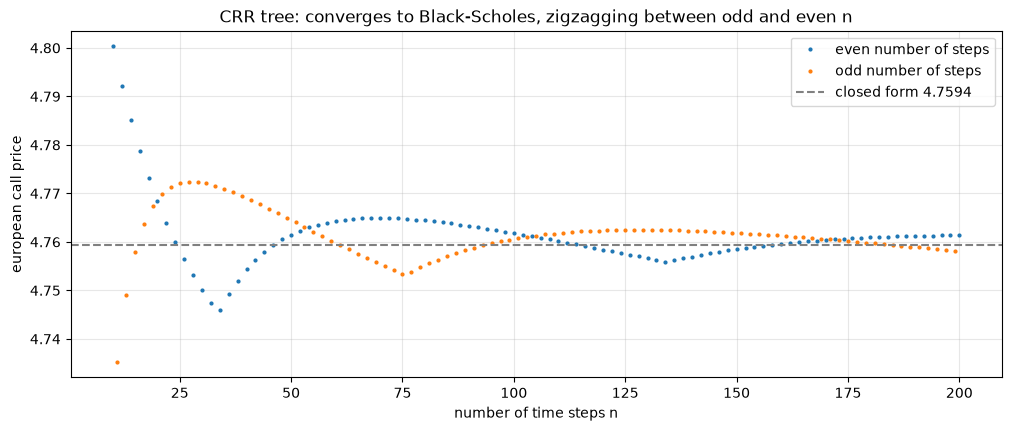

In [4]:
plot_tree_convergence("call", 42, 40, 0.5, 0.10, 0.20)

In [5]:
exact = float(price("call", 42, 40, 0.5, 0.10, 0.20))
for steps in (100, 101, 1000, 1001):
    print(f"n = {steps:>5}: {crr_price('call', 42, 40, 0.5, 0.10, 0.20, steps=steps):.6f}")
avg = 0.5 * (
    crr_price("call", 42, 40, 0.5, 0.10, 0.20, steps=1000)
    + crr_price("call", 42, 40, 0.5, 0.10, 0.20, steps=1001)
)
print(f"average of 1000 and 1001: {avg:.6f}   closed form: {exact:.6f}")

n =   100: 4.761818
n =   101: 4.760785
n =  1000: 4.759817
n =  1001: 4.759090


average of 1000 and 1001: 4.759453   closed form: 4.759422


## 4. American against European

An American put is always worth at least its European twin, and at least what exercising now
pays. Far below the strike the American value touches the payoff line: there, exercising is
optimal, and the option is worth exactly $K - S$.

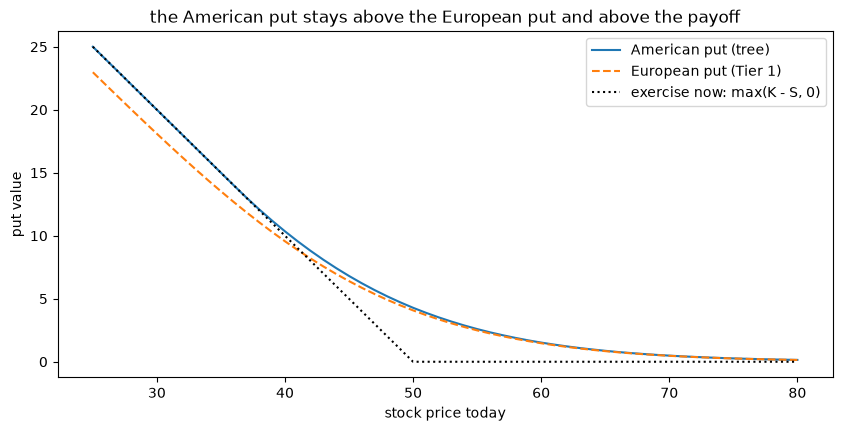

today, S = 50: American 4.2839, European 4.0760


In [6]:
spots = np.linspace(25, 80, 56)
american = [crr_price("put", s, K, T, r, sigma, steps=500, american=True) for s in spots]
european = price("put", spots, K, T, r, sigma)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(spots, american, label="American put (tree)")
ax.plot(spots, european, "--", label="European put (Tier 1)")
ax.plot(spots, np.maximum(K - spots, 0), ":", color="black", label="exercise now: max(K - S, 0)")
ax.set_xlabel("stock price today")
ax.set_ylabel("put value")
ax.set_title("the American put stays above the European put and above the payoff")
ax.legend()
plt.show()
am_today = crr_price("put", S, K, T, r, sigma, steps=2000, american=True)
print(
    f"today, S = 50: American {am_today:.4f}, European {float(price('put', S, K, T, r, sigma)):.4f}"
)

## 5. The PDE grid: how fast it converges

The PDE solver puts the Black-Scholes equation on a grid of log prices and times, and steps
backwards from the payoff with Crank-Nicolson (an average of the explicit and implicit schemes,
accurate to second order). Double the grid in both directions and the error should drop about
4 times: on a log-log chart, a slope of −2. In practice the drops are irregular (9x, then 1.5x,
then 8.5x below): the spot, 42, falls at a different place between two grid nodes on each grid,
so the interpolation error jumps around. On average the slope is −2.

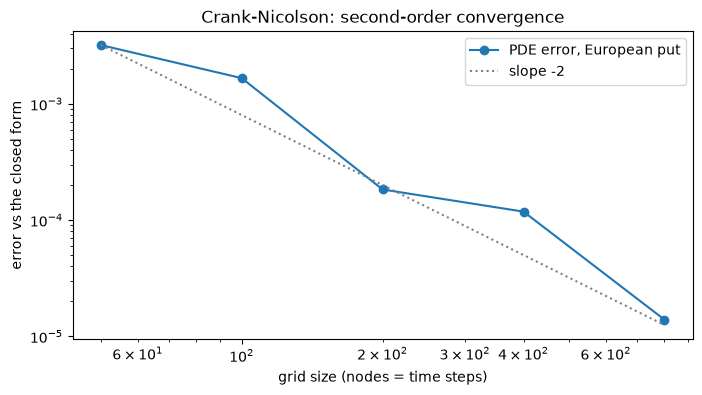

n =   50: error 3.20e-03
n =  100: error 1.66e-03
n =  200: error 1.83e-04
n =  400: error 1.18e-04
n =  800: error 1.39e-05


In [7]:
ns = np.array([50, 100, 200, 400, 800])
exact_put = float(price("put", 42, 40, 0.5, 0.10, 0.20))
errors = np.array(
    [abs(pde_price("put", 42, 40, 0.5, 0.10, 0.20, n_space=n, n_time=n) - exact_put) for n in ns]
)
fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(ns, errors, "o-", label="PDE error, European put")
ax.loglog(ns, errors[0] * (ns[0] / ns) ** 2, ":", color="gray", label="slope -2")
ax.set_xlabel("grid size (nodes = time steps)")
ax.set_ylabel("error vs the closed form")
ax.set_title("Crank-Nicolson: second-order convergence")
ax.legend()
plt.show()
for n, e in zip(ns, errors, strict=True):
    print(f"n = {n:>4}: error {e:.2e}")

## 6. Why the first steps are implicit (Rannacher)

The payoff has a corner at the strike. Crank-Nicolson doesn't damp the wiggles that corner
creates, so the solution "rings": the price is a bit off, and **gamma** (the curvature) near the
strike is garbage. Replacing the first two steps with four small fully implicit steps smooths the
corner away. Below, gamma read off the grid, with and without that start, against the exact
gamma from Tier 1. Only 25 time steps, to make the effect visible.

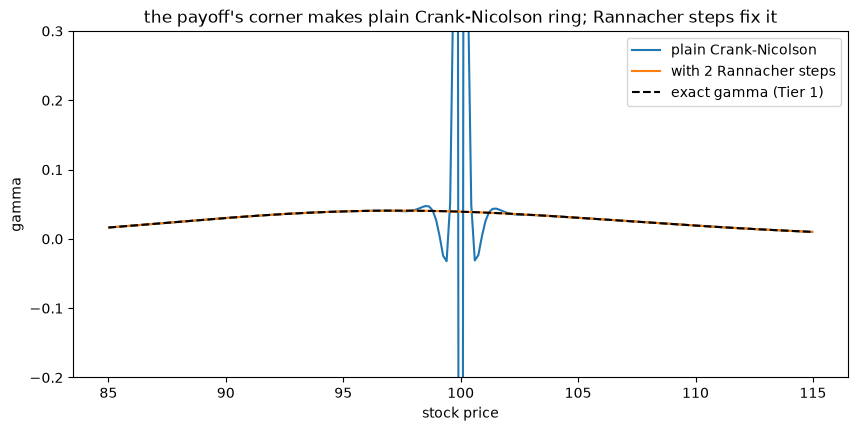

In [8]:
Sg, Kg, Tg, rg, sg = 100.0, 100.0, 0.25, 0.05, 0.2


def grid_gamma(rannacher):
    sol = pde_solve("call", Sg, Kg, Tg, rg, sg, n_space=800, n_time=25, rannacher=rannacher)
    s, v = sol.spots, sol.values
    h1, h2 = s[1:-1] - s[:-2], s[2:] - s[1:-1]
    gam = 2 * (v[2:] * h1 - v[1:-1] * (h1 + h2) + v[:-2] * h2) / (h1 * h2 * (h1 + h2))
    return s[1:-1], gam


fig, ax = plt.subplots(figsize=(10, 4.5))
for ran, label in ((0, "plain Crank-Nicolson"), (2, "with 2 Rannacher steps")):
    s, gam = grid_gamma(ran)
    keep = (s > 85) & (s < 115)
    ax.plot(s[keep], gam[keep], label=label)
s_exact = np.linspace(85, 115, 200)
ax.plot(
    s_exact,
    greeks("call", s_exact, Kg, Tg, rg, sg).gamma,
    "--",
    color="black",
    label="exact gamma (Tier 1)",
)
ax.set_ylim(-0.2, 0.3)
ax.set_xlabel("stock price")
ax.set_ylabel("gamma")
ax.set_title("the payoff's corner makes plain Crank-Nicolson ring; Rannacher steps fix it")
ax.legend()
plt.show()

## 7. When to exercise: the early exercise boundary

For an American put, at each moment there is a stock price $S^*(t)$ below which exercising now is
optimal. Far from expiry it's well below the strike (waiting is worth a lot); as expiry gets
close it rises toward the strike. The PDE solver records it at every time step (the steps in the
line are the grid spacing).

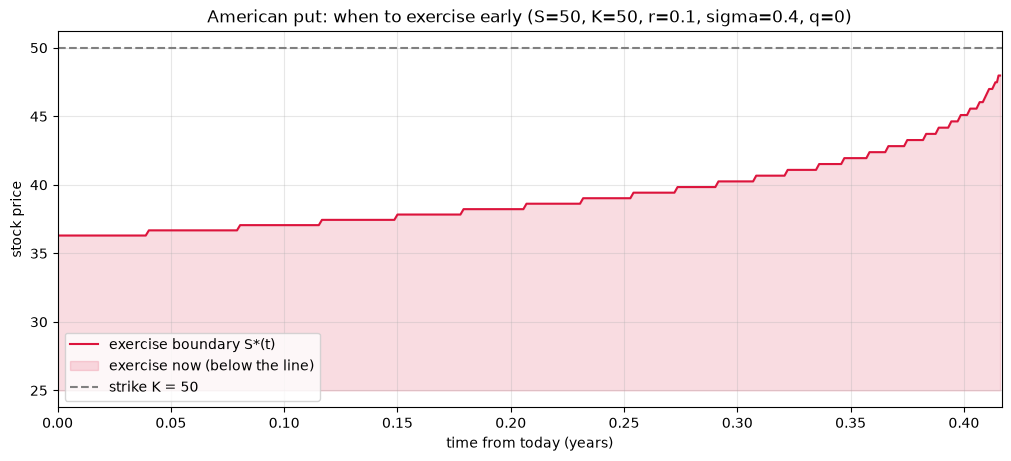

In [9]:
plot_exercise_boundary("put", S, K, T, r, sigma)

## 8. Tree and PDE agree

Two completely different methods, same answer: the stated tolerance is 0.05% of the price, with
the tree at 2000/2001 steps (averaged) and the PDE on a 300 x 300 grid.

In [10]:
cases = [
    ("Hull's put", (50, 50, 5 / 12, 0.10, 0.40, 0.0)),
    ("Tier 1 put", (42, 40, 0.5, 0.10, 0.20, 0.0)),
    ("OTM 1 year", (100, 110, 1, 0.05, 0.25, 0.0)),
    ("2 years, dividends", (100, 90, 2, 0.03, 0.30, 0.02)),
]
print(f"{'case':20s} {'tree':>10s} {'pde':>10s} {'gap':>8s} {'European':>10s} {'premium':>8s}")
for name, a in cases:
    tree = 0.5 * (
        crr_price("put", *a, steps=2000, american=True)
        + crr_price("put", *a, steps=2001, american=True)
    )
    pde = pde_price("put", *a, american=True, n_space=300, n_time=300)
    eur = float(price("put", *a))
    gap = abs(tree - pde) / tree
    print(f"{name:20s} {tree:10.5f} {pde:10.5f} {gap:7.3%} {eur:10.5f} {tree - eur:8.4f}")

case                       tree        pde      gap   European  premium


Hull's put              4.28436    4.28295  0.033%    4.07598   0.2084


Tier 1 put              0.91020    0.91000  0.021%    0.80860   0.1016


OTM 1 year             13.74315   13.74177  0.010%   12.66162   1.0815


2 years, dividends     10.38288   10.37936  0.034%   10.17738   0.2055


## 9. American calls: worth nothing extra without dividends

Exercising a call early gives you the stock now and costs you the strike now. Without dividends
that's never better than waiting: you'd pay K earlier (losing interest) and give up the
protection of the option. So an American call on a non-dividend stock is worth exactly the
European call. With a dividend yield, holding the stock pays something the option doesn't, and
early exercise can become worth it.

In [11]:
a0 = (42, 40, 0.5, 0.10, 0.20)
print(
    f"no dividends:  American {crr_price('call', *a0, steps=1000, american=True):.6f}, "
    f"European tree {crr_price('call', *a0, steps=1000):.6f}"
)
for q in (0.0, 0.04, 0.08):
    a = (100, 80, 1, 0.03, 0.25, q)
    am = crr_price("call", *a, steps=2000, american=True)
    eu = crr_price("call", *a, steps=2000)  # same tree, so the tree's own error cancels
    print(
        f"q = {q:.0%}: American {am:.4f}, European {eu:.4f}, early exercise premium {am - eu:.4f}"
    )

no dividends:  American 4.759817, European tree 4.759817
q = 0%: American 24.1466, European 24.1466, early exercise premium 0.0000
q = 4%: American 21.3967, European 20.7950, early exercise premium 0.6017
q = 8%: American 20.2639, European 17.7238, early exercise premium 2.5401


## 10. Try it yourself

1. In the cell below, write the backward loop of a tree yourself (with `backward_step` or plain
   Python) and check that you get Hull's 4.4885 for the 5-step American put.
2. In section 4, add an American **call** with a dividend yield of 8%. Where does its value touch
   the payoff line?
3. In section 6, try `n_time=200` with `rannacher=0`. Does the ringing go away by itself?

In [12]:
# your backward loop here, compare w/ Hull's 4.4885 (crr_price w/ steps=5, american=True)